# Uber Pickup Demand Analysis — April–September 2014

End-to-end reproducible workflow for input validation, top-down geographic classification, temporal and borough analysis, visualizations, and statistical summaries. Run from the project root with the project virtual environment active. Raw CSV files are retained unchanged.

## 1. Execute the complete analysis pipeline
The pipeline validates all six monthly datasets, retains duplicate rows, assigns NYC membership before boroughs, and classifies outside-city points separately.

In [1]:
import os
from pathlib import Path
root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent
os.chdir(root)
from src.analysis import main
main()

{
  "n": 4534327,
  "nyc_n": 4411894,
  "outside_n": 122433,
  "unmatched_inside": 0,
  "outside_unmatched": 49,
  "boundary_points": 0,
  "inside_state_unmatched": 15,
  "monthly_counts": {
    "4": 564516,
    "5": 652435,
    "6": 663844,
    "7": 796121,
    "8": 829275,
    "9": 1028136
  },
  "hour_counts": {
    "0": 103836,
    "1": 67227,
    "2": 45865,
    "3": 48287,
    "4": 55230,
    "5": 83939,
    "6": 143213,
    "7": 193094,
    "8": 190504,
    "9": 159967,
    "10": 159148,
    "11": 165703,
    "12": 170452,
    "13": 195877,
    "14": 230625,
    "15": 275466,
    "16": 313400,
    "17": 336190,
    "18": 324679,
    "19": 294513,
    "20": 284604,
    "21": 281460,
    "22": 241858,
    "23": 169190
  },
  "weekday_counts": {
    "0": 541472,
    "1": 663789,
    "2": 696488,
    "3": 755145,
    "4": 741139,
    "5": 646114,
    "6": 490180
  },
  "boroughs": [
    {
      "borough": "Manhattan",
      "pickups": 3443457,
      "pct_nyc": 78.04940463211491,
   

## 2. Review validation and geographic reconciliation
Percentages in the borough table are reported against both NYC-only and all-record denominators.

In [2]:
import pandas as pd
from IPython.display import display
quality = pd.read_csv('outputs/tables/monthly_data_quality.csv')
boroughs = pd.read_csv('outputs/tables/borough_summary.csv')
reconciliation = pd.read_csv('outputs/geographic/geographic_reconciliation.csv')
geo_quality = pd.read_csv('outputs/geographic/geographic_data_quality.csv')
display(quality, boroughs, reconciliation, geo_quality)

,month,rows,expected_rows,duplicate_rows,missing_cells,invalid_rows,wrong_month_rows,rows_match_expected
0,Apr,564516,564516,7749,0,0,0,True
1,May,652435,652435,10075,0,0,0,True
2,Jun,663844,663844,10686,0,0,0,True
3,Jul,796121,796121,14152,0,0,0,True
4,Aug,829275,829275,15882,0,0,0,True
5,Sep,1028136,1028136,24037,0,0,0,True


,borough,pickups,pct_nyc,pct_all
0,Manhattan,3443457,78.049405,75.941964
1,Brooklyn,593595,13.454426,13.091138
2,Queens,342224,7.756850,7.547404
3,Bronx,31584,0.715883,0.696553
4,Staten Island,1034,0.023437,0.022804


,Unnamed: 0,records
0,New York,4441067
1,New Jersey,92649
2,Connecticut,546
3,Massachusetts,1
4,Other classified states,0
5,Unmatched,64


,measure,count,denominator
0,Total pickup records,4534327,all records
1,Inside NYC boundary,4411894,all records
2,Outside NYC boundary,122433,all records
3,Inside NYC without borough match,0,inside NYC
4,Outside NYC unmatched to state,49,outside NYC
5,Inside NYC unmatched to 2014 state polygon,15,inside NYC
6,NYC boundary points,0,all records
7,Suspicious geography total,65,all records


## 3. Statistical results
Omnibus tests are interpreted with effect sizes. Their p-values should be treated cautiously because pickup records are temporally and spatially clustered.

In [3]:
tests = pd.read_csv('outputs/tables/statistical_tests.csv')
display(tests)

,question,test,statistic,df,p_value,cramers_v,n,effect_size_cohens_w,date_exposures
0,Is hour associated with day of week?,Pearson chi-square independence,305696.583205,138,0.0,0.106002,4534327,NaN,NaN
1,Does month-hour distribution vary across months?,Pearson chi-square independence,12423.436687,115,0.0,0.023409,4534327,NaN,NaN
2,Does hourly pickup profile differ by borough?,Pearson chi-square independence,47371.173363,92,0.0,0.051810,4411894,NaN,NaN
3,Are Uber base and borough pickup distributions...,Pearson chi-square independence,16095.661326,16,0.0,0.030200,4411894,NaN,NaN
4,Does mean demand per calendar date differ by w...,Chi-square goodness of fit adjusted for weekda...,91187.261175,6,0.0,NaN,4534327,0.141811,"[26, 27, 26, 26, 26, 26, 26]"


## 4. Generated visualizations
Maps and charts are also saved to `outputs/figures/` and regenerated by the analysis pipeline.

usa_pickup_hexbin.png


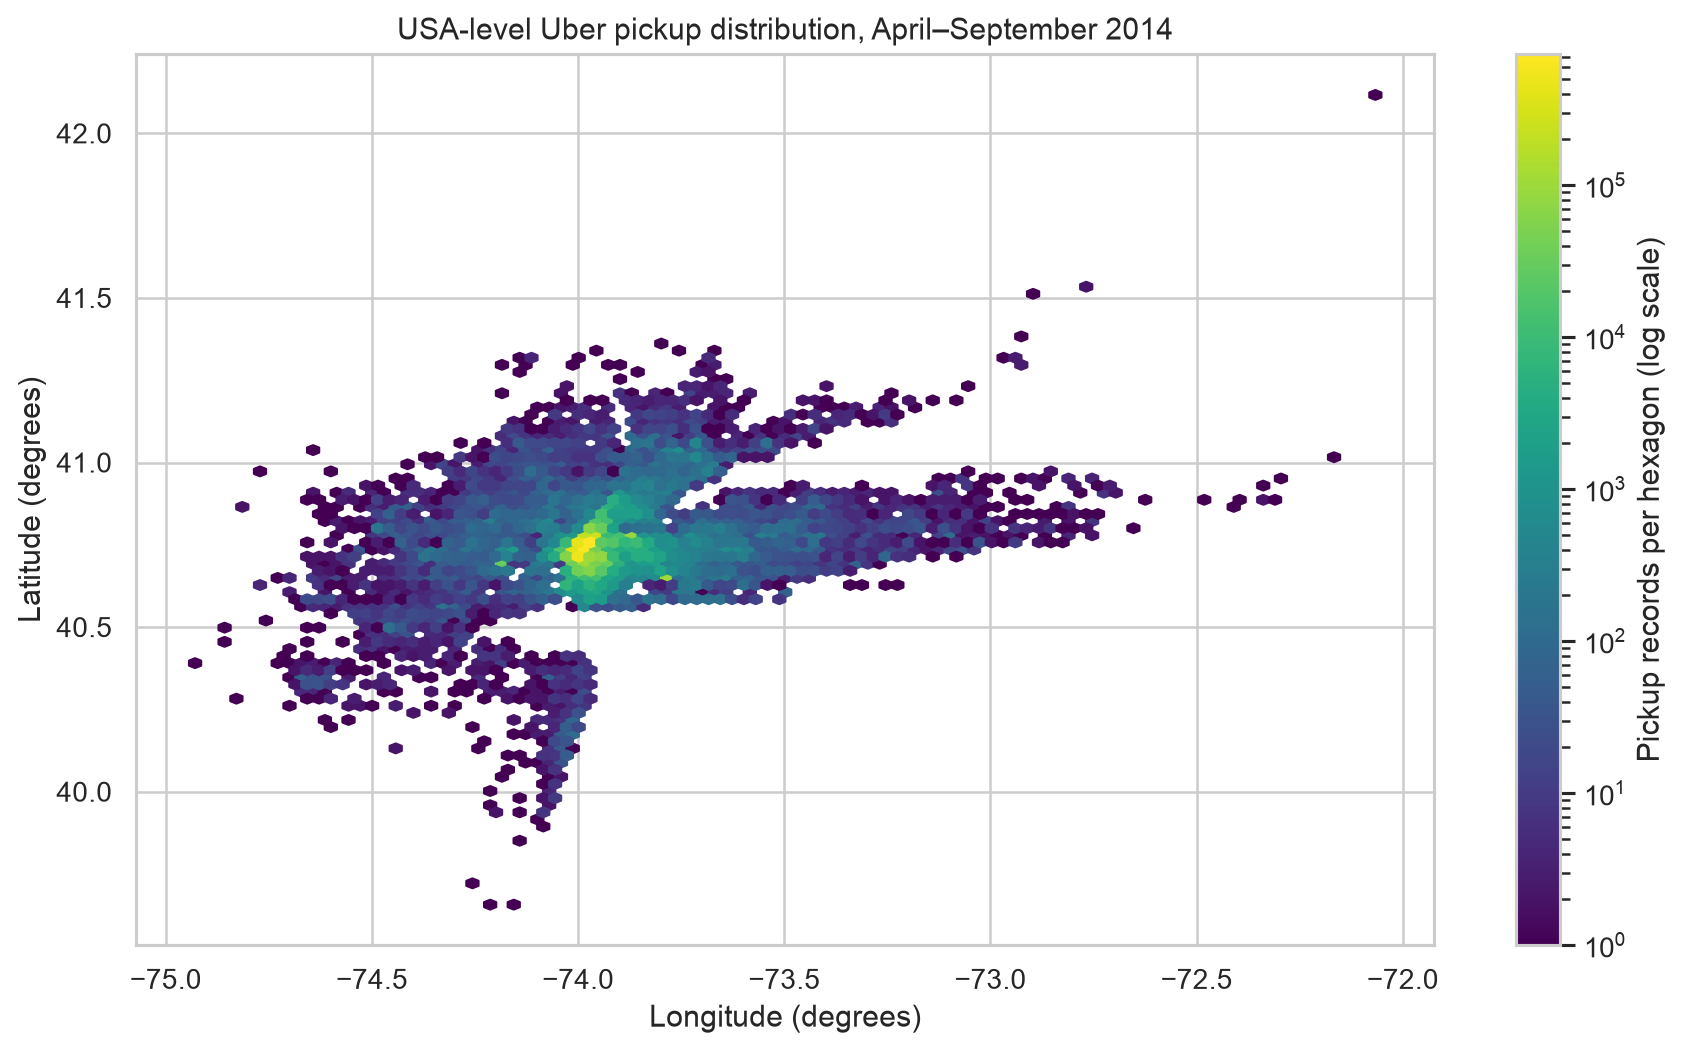

nyc_boundary_classification.png


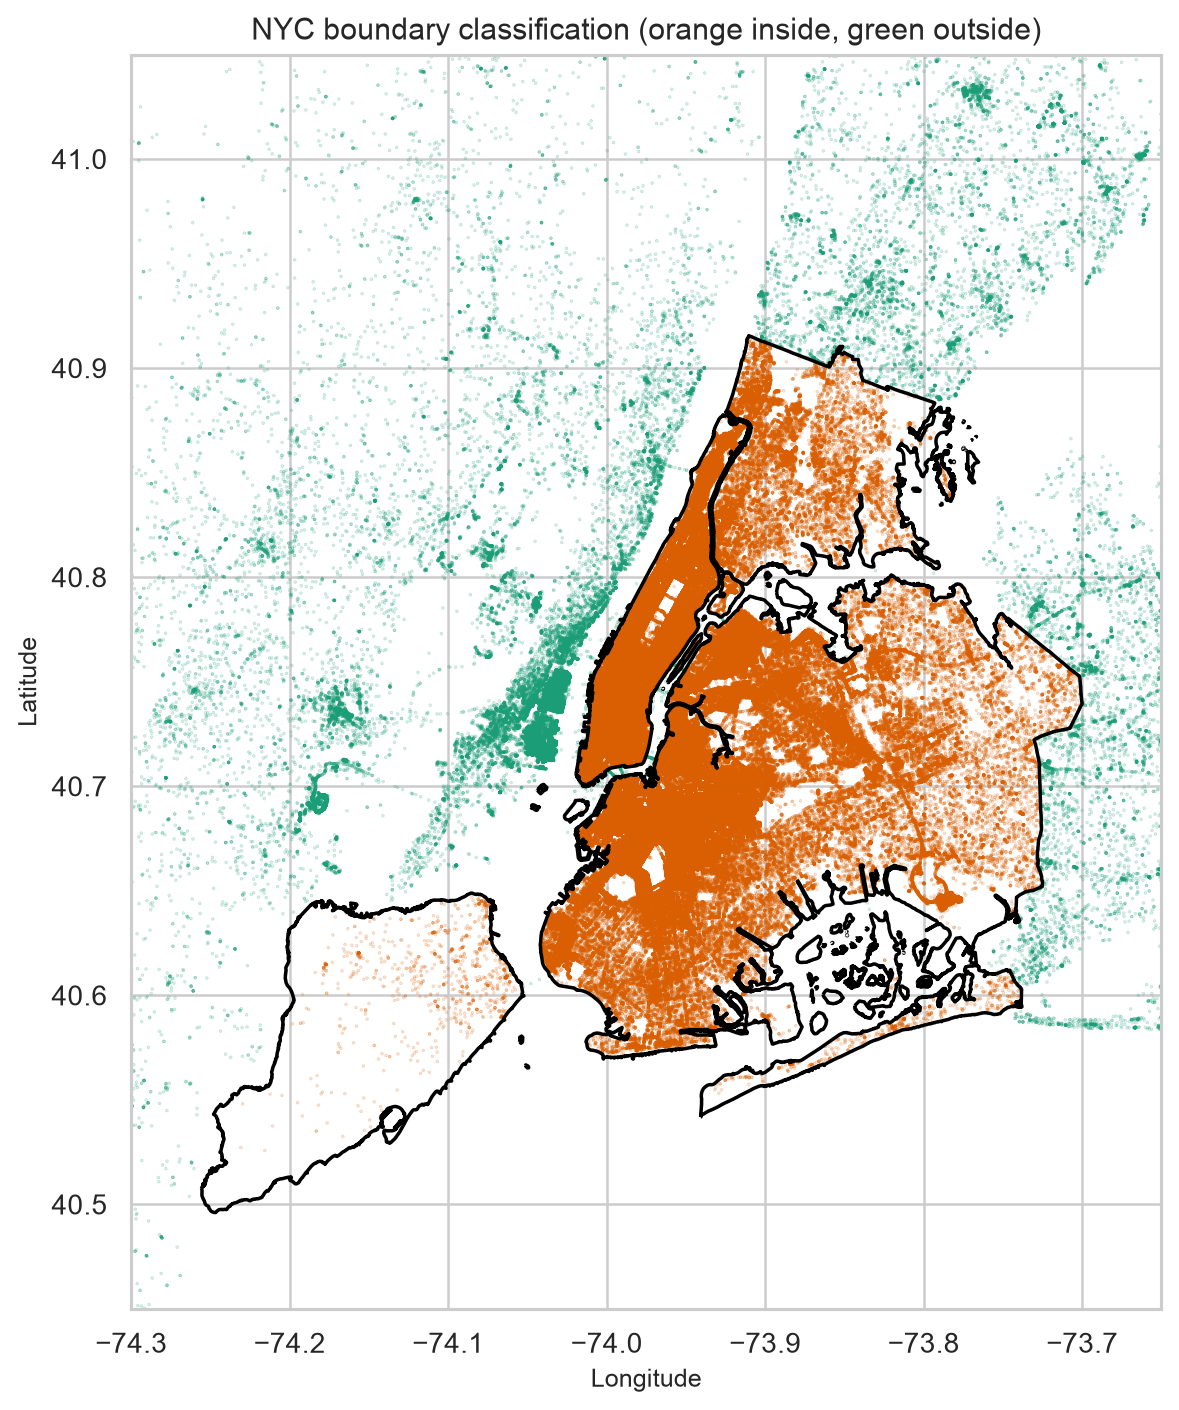

nyc_borough_choropleth.png


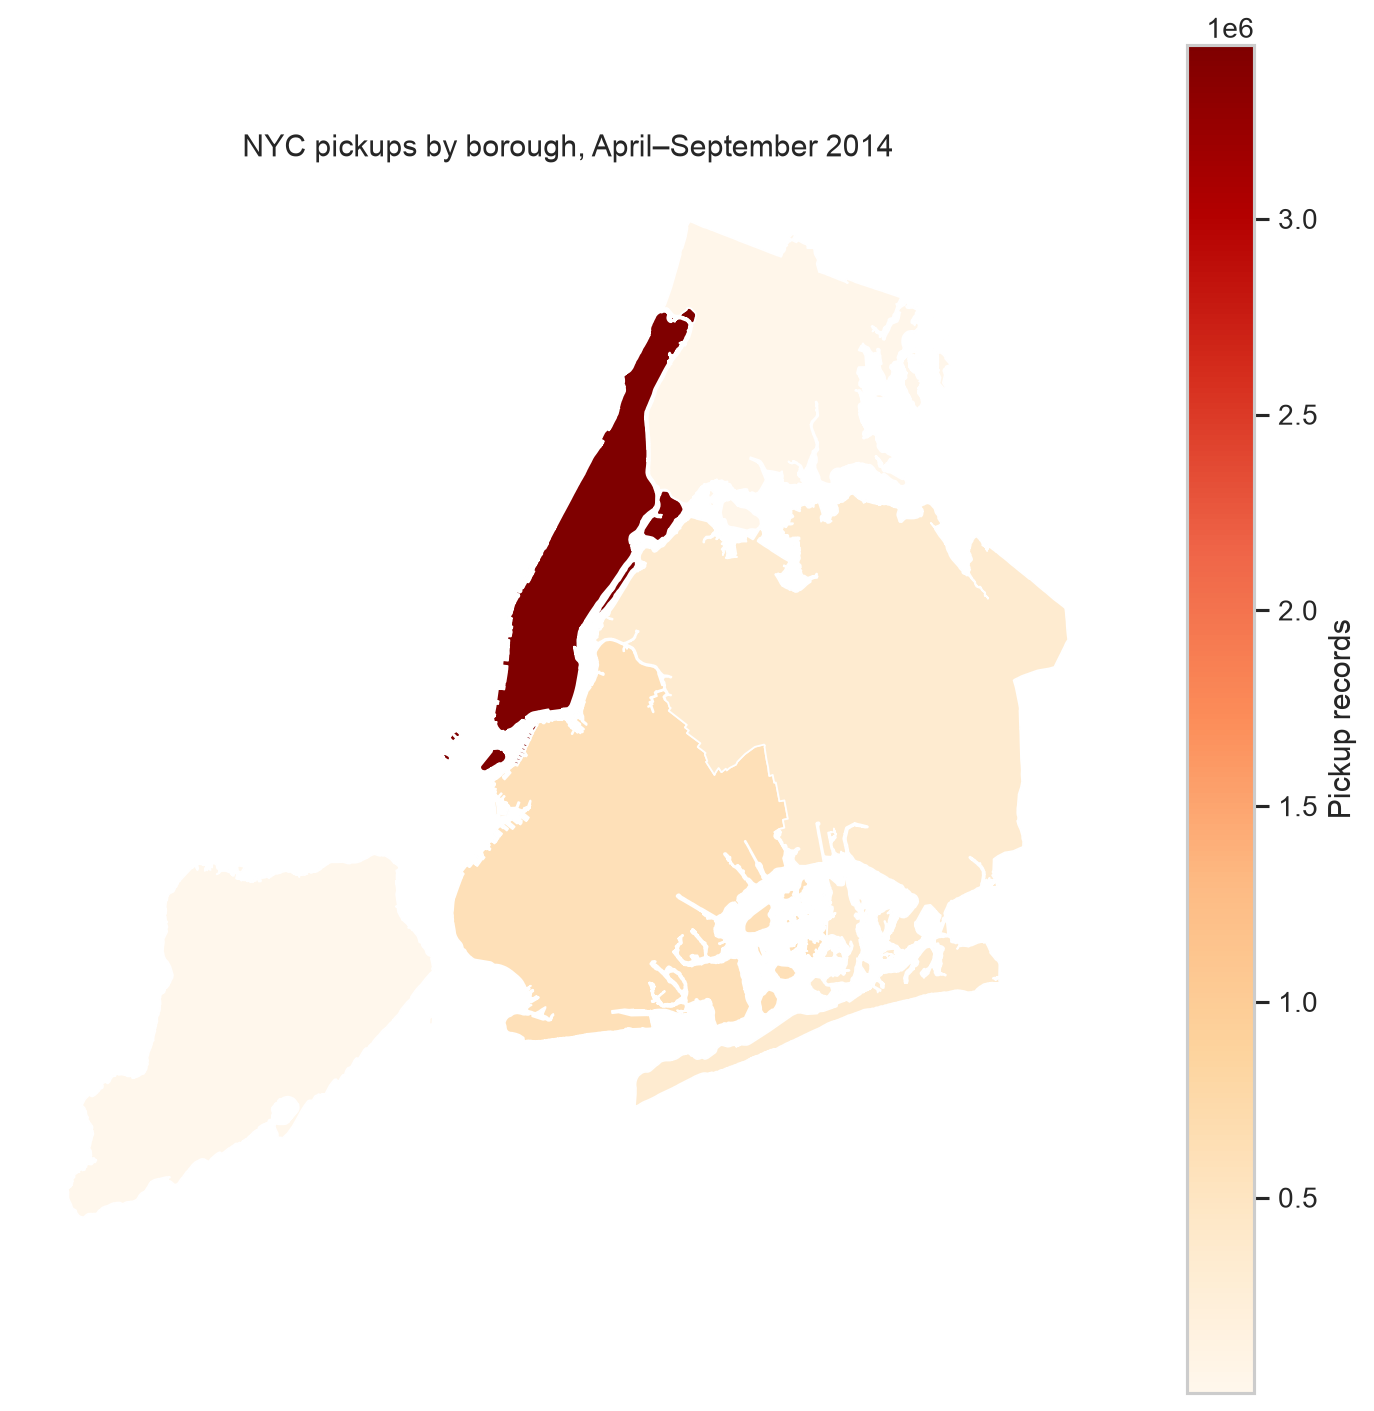

monthly_demand.png


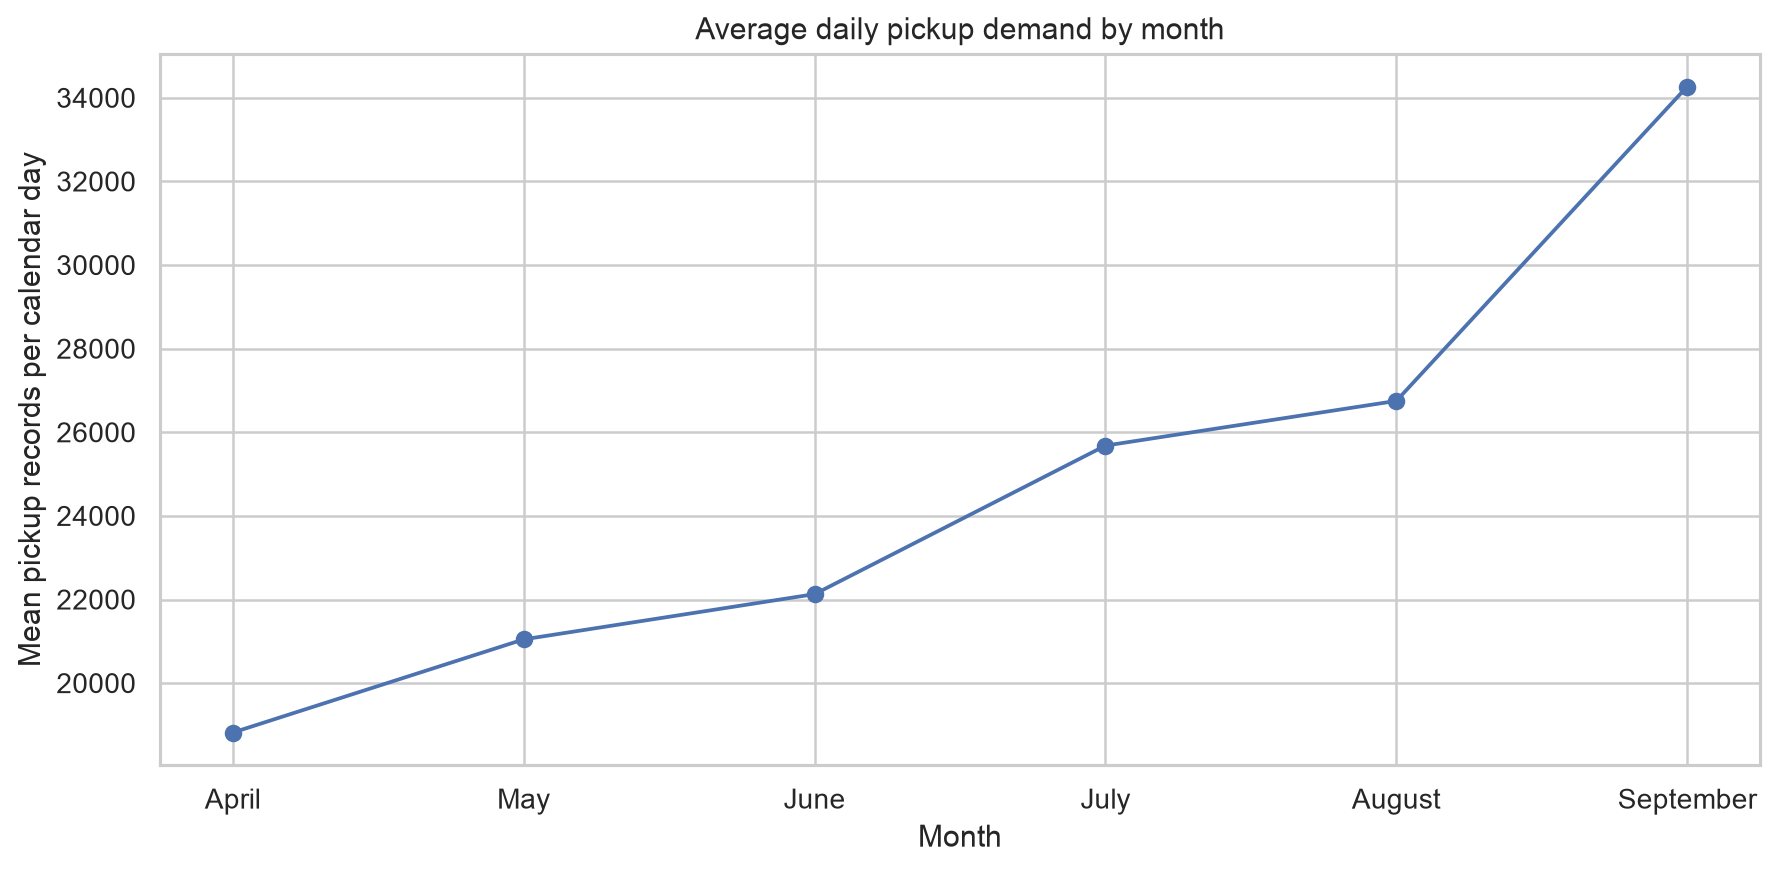

hourly_demand.png


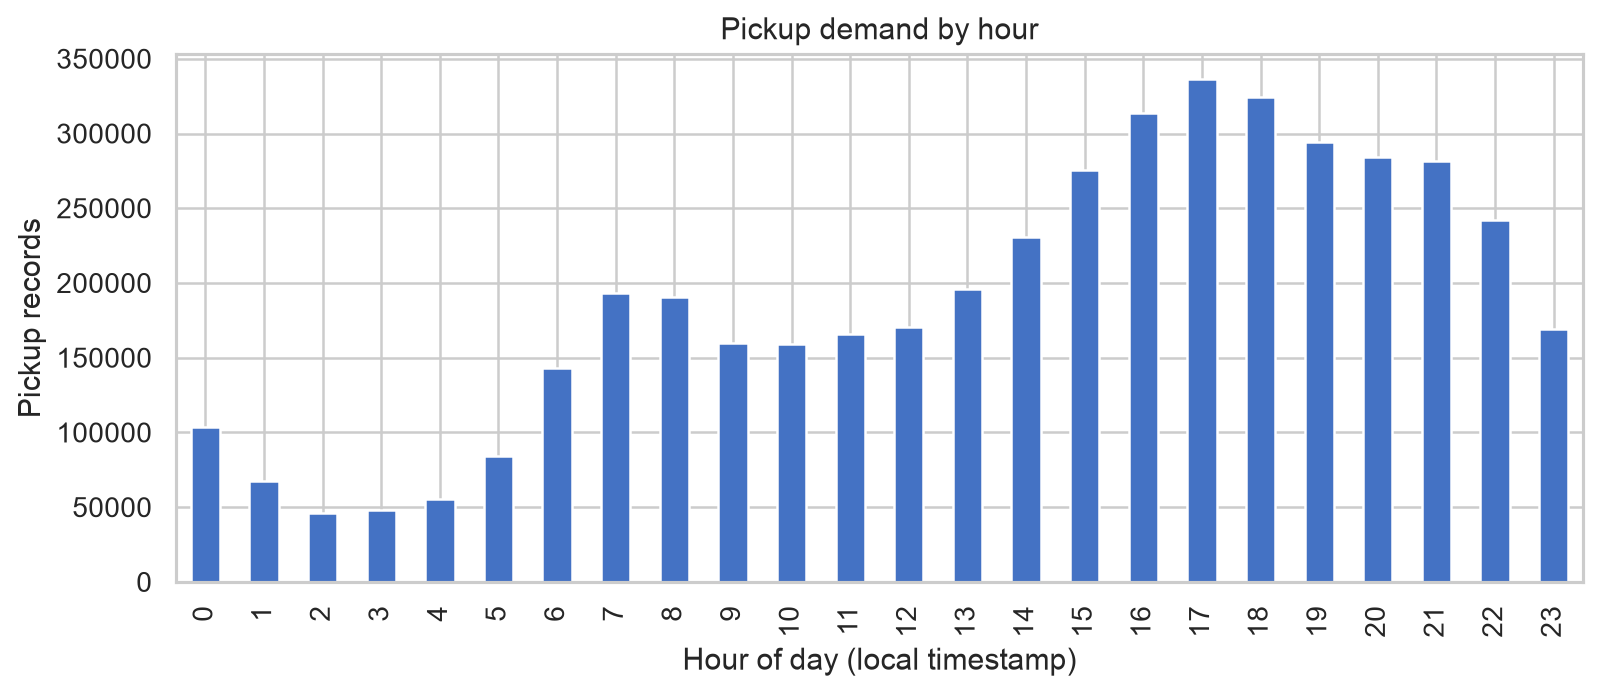

day_hour_heatmap.png


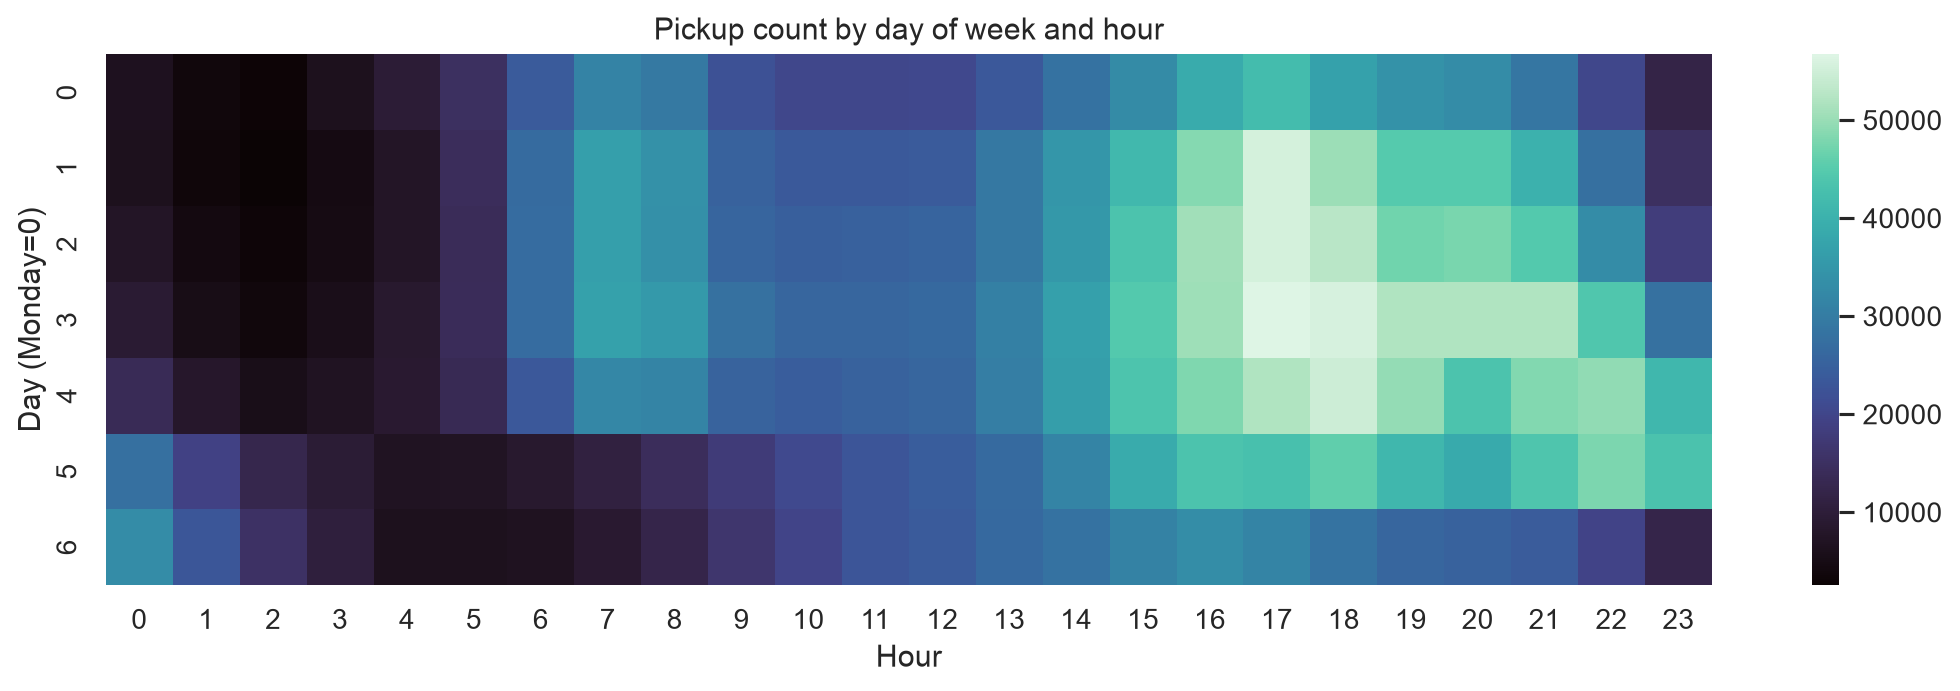

month_hour_heatmap.png


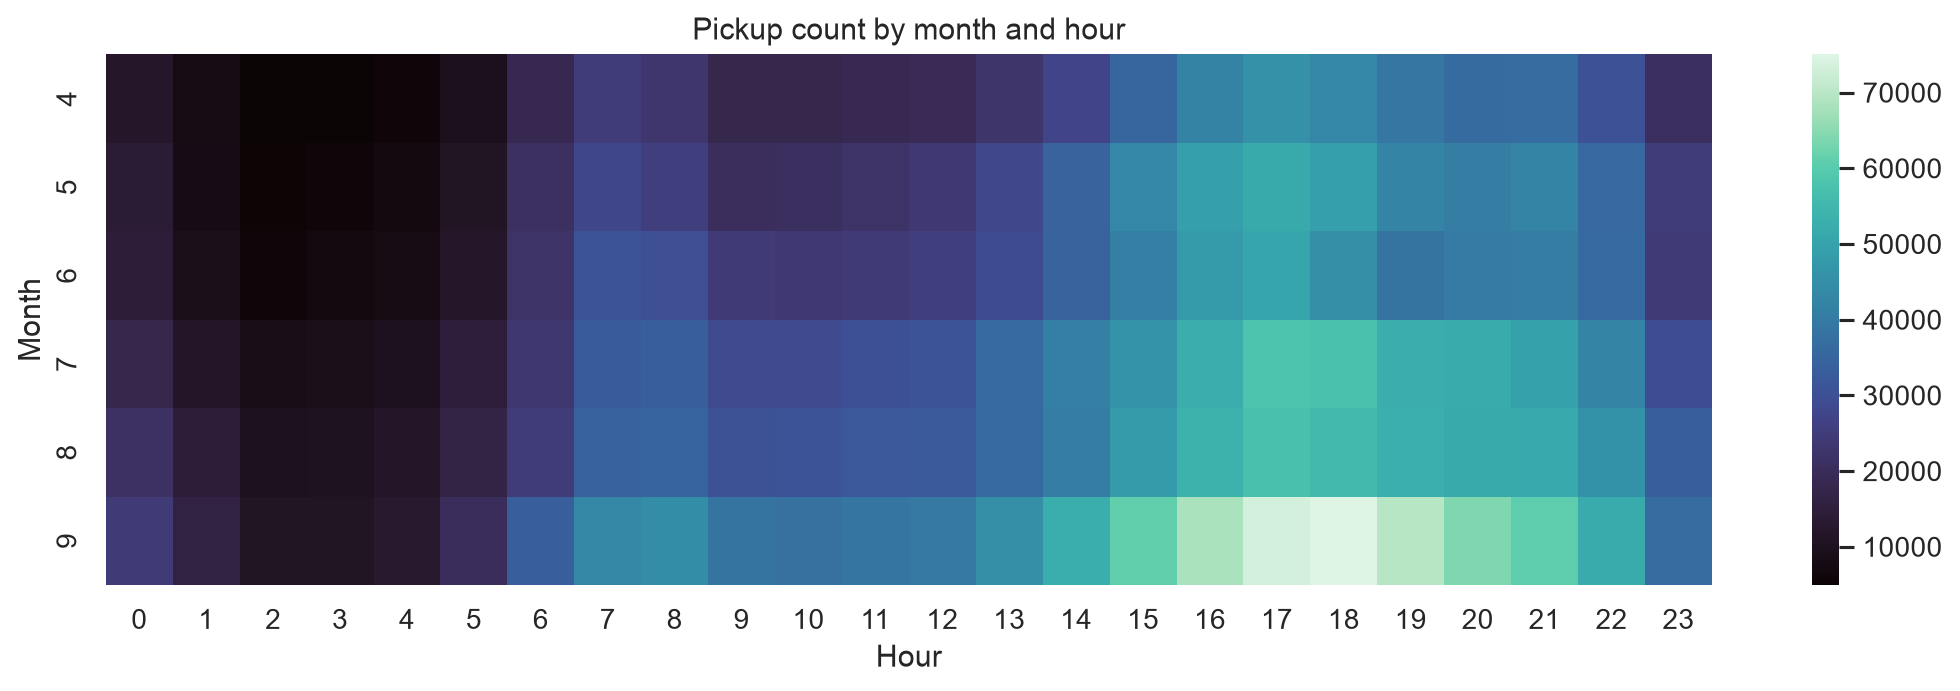

weekday_weekend.png


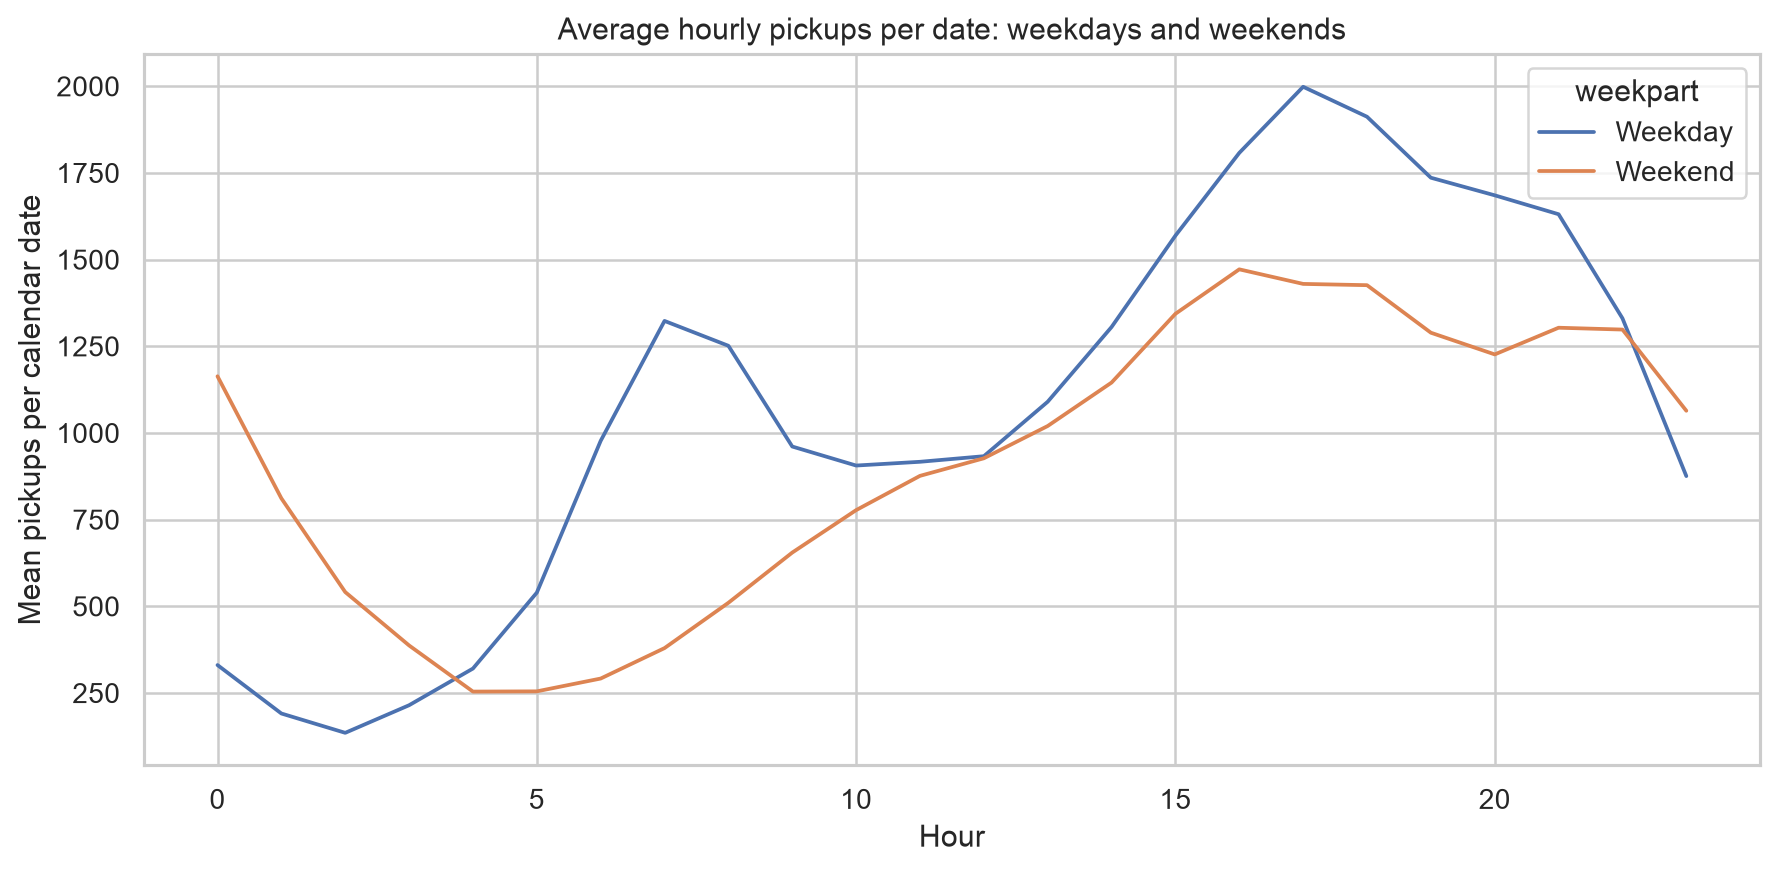

borough_hourly_profiles.png


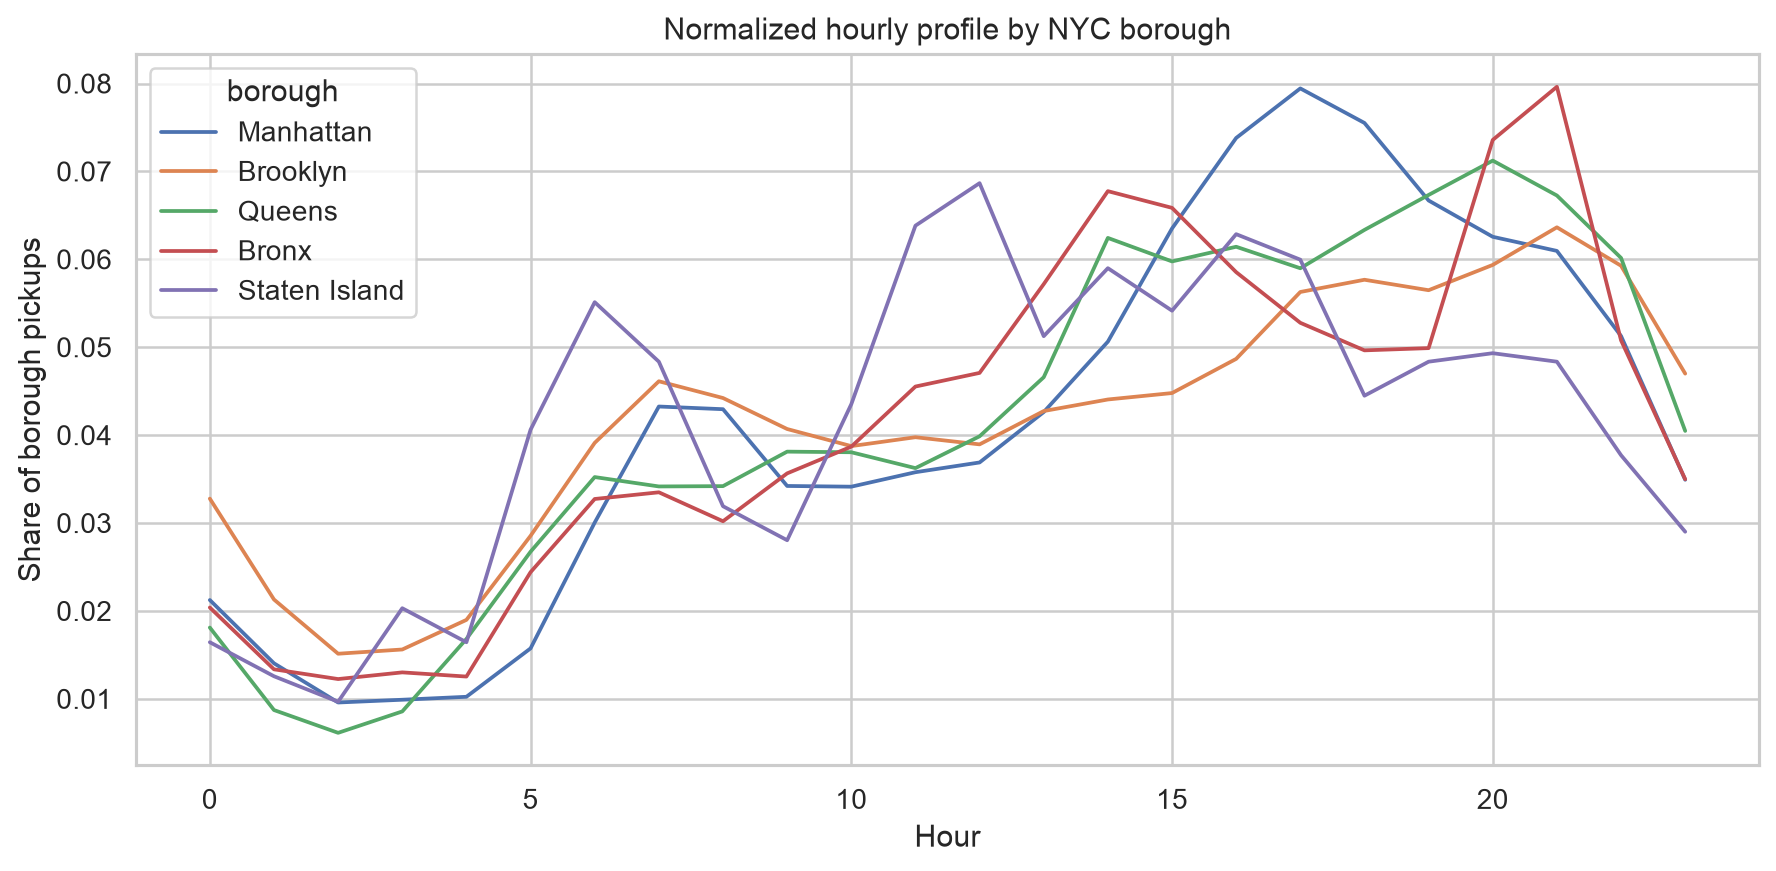

In [4]:
from IPython.display import display, Image
for name in ['usa_pickup_hexbin.png','nyc_boundary_classification.png','nyc_borough_choropleth.png','monthly_demand.png','hourly_demand.png','day_hour_heatmap.png','month_hour_heatmap.png','weekday_weekend.png','borough_hourly_profiles.png']:
    print(name)
    display(Image(filename='outputs/figures/'+name))